# ![alt text](https://upload.wikimedia.org/wikipedia/commons/c/c3/Python-logo-notext.svg)  **Modelo Primer parcial** ![alt text](https://upload.wikimedia.org/wikipedia/commons/c/c3/Python-logo-notext.svg)  




### **Ejercicio 1**

Escribir la función recursiva **tieneRepetidos(vector)**, que retorna True si vector tiene al menos un elemento repetido y False en caso contrario. Las soluciones que NO sean recursivas no serán tomadas en cuenta.

Por ejemplo:

Si arr1 = [5, 10, 9, 8, 13, 21] y arr2 = [3, 13, 8, 9, 8, 5]

=> **tieneRepetidos(arr1)** devuelve False y **tieneRepetidos(arr2)** devuelve True

Ayuda: Pueden pensar en escribir una función que busque un elemento dentro de un vector. Al menos una de las funciones implementadas debe ser recursiva (principal o auxiliares).


In [ ]:
import numpy as np

#incluido(elemento, vector) -> True si elemento esta en vector
#[10,2,3,1,4,3] 1
#tieneRepetidos(vector) = True                       vector[0] esta en el resto(vector[1:])
#                         False                      vector vacio
#                         tieneRepetidos(vector[1:])

#incluido(elemento, vector) = True                            si elemento == vector[0]
#                             False                           si vector esta vacio
#                             incluido(elemento, vector[1:])
def incluido(vector:np.array,elemento:int) -> bool:
  if(len(vector) == 0):
    resultado = False
  elif(vector[0] == elemento):
    resultado = True
  else:
    resultado = incluido(vector[1:],elemento)
  return resultado

def tieneRepetidos(vector:np.array) -> bool:
  if(len(vector) == 0):
    hayRepetido = False
  elif(incluido(vector[1:],vector[0])):
    hayRepetido = True
  else:
    hayRepetido = tieneRepetidos(vector[1:])
  return hayRepetido

vector = np.array([10,2,2,1,4,3])
print(tieneRepetidos(vector))


True


In [ ]:
arr1 = [5, 10, 9, 8, 13, 21]
arr2 = [3, 13, 8, 9, 8, 5]

print(incluidoIT(9,arr1))
print(incluido(8,arr2))

In [ ]:
arr1 = [5, 10, 9, 8, 13, 21]
arr2 = [3, 13, 8, 9, 8, 5]

print(tieneRepetidos(arr1))
print(tieneRepetidos(arr2))

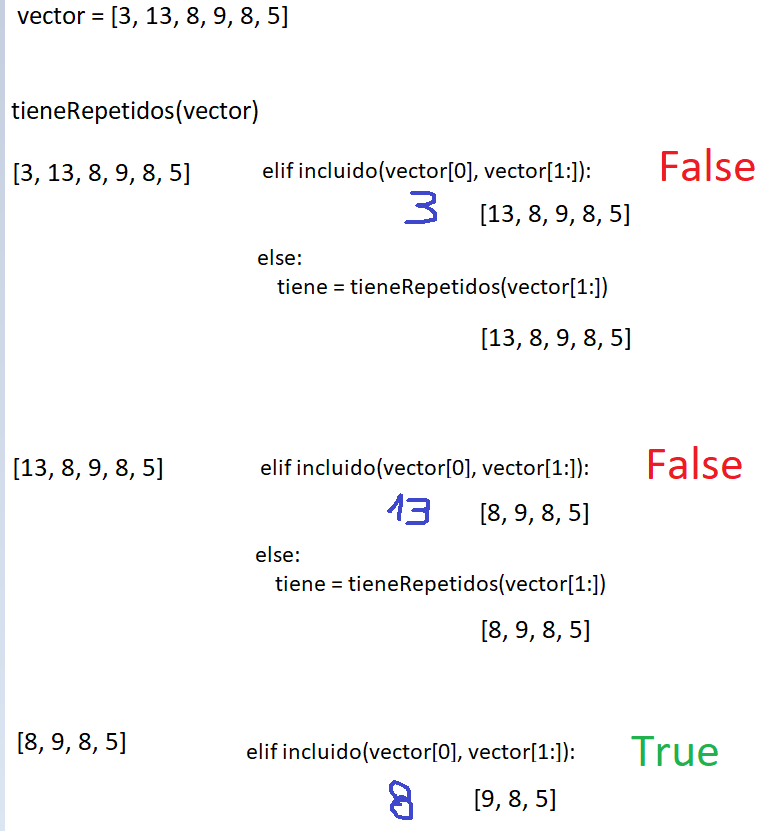

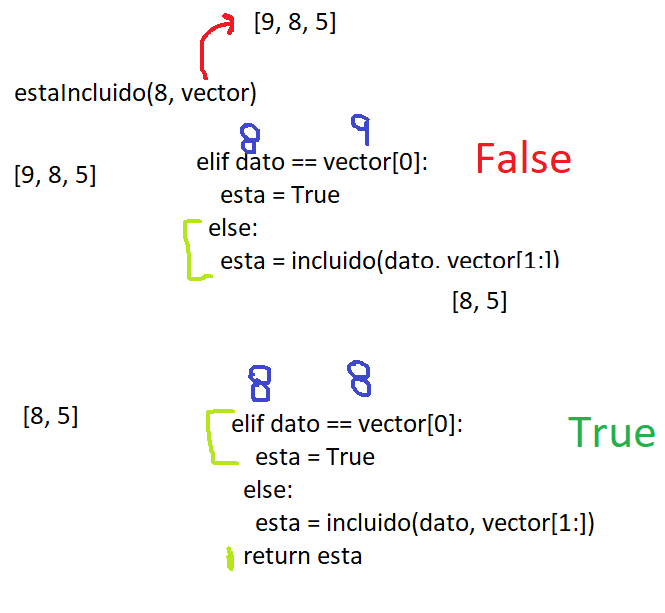

### **Ejercicio 2**

El gobierno nacional decidió llevar adelante un plan de granjas de agricultura agroecológica para garantizar la soberanía alimentaria de la población. Para eso nos pide desarrollar un software para diseñar la distribución de las plantas en los bancales.

Una planta se define con:

- Un nombre
- Un tipo: “hoja” o “fruto”
- Una fecha de siembra (para simplificar la modelamos como **int**).

Las plantas en los bancales se distribuyen en hileras (filas) de plantas, donde todas las hileras tienen la misma cantidad. Para ubicar las plantas tenemos la condición que dentro de la misma hilera no puede haber dos plantas seguidas del mismo tipo (“hoja” o “fruto”) para garantizar el cuidado del agrosistema. Notar que la condición solo aplica entre las plantas que forman parte de una misma hilera (fila) pero no hay ninguna restricción entre las plantas en una hilera y las de sus hileras vecinas.

Implementar el TDA **Bancal** que contenga al menos las siguientes operaciones:

-  **__init__(cantHileras, cantPlantasPorHilera):** que recibe el tamaño del bancal.

- **ubicarPlanta(nombrePlanta, tipoPlanta, fechaSiembra)**: que recibe los datos de la planta y la ubica en el bancal retornando la posición (fila y columna). Si la planta no puede ser ubicada por alguna razón, se debe lanzar una excepción. Recordar que no pueden ir dos plantas del mismo tipo seguidas en la misma fila.

- **cosecharPlanta(fechaActual):** que recibe la fecha actual (int), saca del bancal y retorna la primera planta que encuentre que haya sido plantada hace 20 días o más. Si no hay ninguna planta para cosechar se debe retornar None.

- **__repr__():** que muestra la distribución de las plantas en el bancal.

Ayuda:  Implementar primero el TDA Planta.

####Notas:


- No son las únicas operaciones necesarias, agregar las operaciones y funciones que consideren necesarias.
-  Una bancal vacio contiene None o cero en todas las posiciones.
- Los bancales tienen siempre 2 o más plantas por hilera



In [ ]:
def validarTipo(variable:any, nombre:str, tipo:type)->any:
  if not isinstance(variable, tipo):
    raise Exception(f"La variable {nombre} debe ser de tipo {tipo}.")
  return variable

#Para poder hacer esto se deben usar punteros a funcion, sino con el tipo incorrecto la condicion se evalua antes
#de llamar a la funcion y va a fallar
def validarTipoCondicion(variable:any, nombre:str, tipo:type, condicion:bool = True):
  validarTipo(variable, nombre, tipo)
  if not condicion:
    raise Exception(f"La variable {nombre} no cumple la condición.")
  return variable

def validarNumeroPositivo(numero:int, nombre:str, tipo:type)->int:
  validarTipo(numero, nombre, tipo)
  if numero < 0:
    raise Exception(f"La variable {nombre} debe contener un numero positivo.")
  return numero

In [ ]:
class Planta:
  def __init__(self,nombre:str,tipo:str,fechaSiembra:int):
    self.__nombre = validarTipo(nombre,"nombre",str)
    self.__tipo = validarTipoCondicion(tipo,"tipo",str,("hoja","fruto"))
    self.__fechaSiembra = validarNumeroPositivo(fechaSiembra,"fechaSiembra",int)

  def __str__(self) -> str:
    return f"{self.__nombre} {self.__tipo} {self.__fechaSiembra}"

  def mismoTipo(self,tipoDePlanta) -> bool:
    return self.__tipo != tipoDePlanta

class Bancal:
  def __init__(self,cantHileras:int, cantPlantasPorHilera:int):
    self.__cantHileras = validarNumeroPositivo(cantHileras,"cantHileras",int)
    self.__cantPlantasPorHilera = validarNumeroPositivo(cantPlantasPorHilera,"cantPlantasPorHilera",int)
    self.__granja = np.empty((cantHileras,cantPlantasPorHilera),Planta)

  def __repr__(self) -> str:
    return f"{self.__granja}"

  def ubicarPlanta(nombrePlanta:str, tipoPlanta:str, fechaSiembra:int) -> int:
    hilera,planta = self.__granja.shape
    for posHilera in range(hilera):
      for posPlanta in range(planta):
        if((self.__granja[posHilera][posPlanta] == None) and (self.__granja[posHilera][posPlanta + 1].mismoTipo(tipoPlanta) and self.__granja[posHilera][posPlanta - 1].mismoTipo(tipoPlanta)))
          self.__granja[posHilera][posPlanta] = Planta(nombrePlanta,tipoPlanta,fechaSiembra)
          return posHilera,posPlanta
    else:


In [ ]:
# creamos una bancal con un 5 hileras de 4 plantas

bancal = Bancal(5,4)

bancal = Bancal(5,4)
bancal.ubicarPlanta("lechuga", "hoja", 1)
bancal.ubicarPlanta("acelga", "hoja", 1)
bancal.ubicarPlanta("tomate","fruto", 2)
bancal.ubicarPlanta("rucula", "hoja", 2)
bancal.ubicarPlanta("habas", "fruto", 3)
bancal.ubicarPlanta("morron", "fruto", 3)
bancal.ubicarPlanta("limon", "fruto", 3)
print(bancal)

bancal.cosecharPlanta(22) #retorna la lechuga de la posicion 0,0

array([[lechuga:1, tomate:2, acelga:1, habas:3],
       [rucula:2, morron:3, None, limon:3],
       [None, None, None, None],
       [None, None, None, None],
       [None, None, None, None]], dtype=object)


lechuga:1